# ****1. Data Preprocessing****

First, We need to get train images and we scaled each images by 80 x 80 px in order to train faster the CNN Model. Also here, we get image labels from folder name.

In [ ]:
import os
import zipfile
import cv2
from glob import glob
import numpy as np
import pandas as pd

# Load the training data
train_image_file_path = '../input/plant-seedlings-classification/train/*/*.png'

# Get a list of all image file paths
image_files = glob(train_image_file_path)

# Print the number of image files found
print(f"Found {len(image_files)} image files")

# Initialize lists to store the training images and labels
training_images = []
training_labels = []

# Define the scale for resizing images
scale = 80  # Adjust this value as needed (For 1st case we use it as 70, for 2nd case we used it as 140)

# Loop over each image file
for count, image_file in enumerate(image_files, start=1):
    print(f"Processing image {count} of {len(image_files)}", end='\r')

    # Read the image file and resize it
    image = cv2.resize(cv2.imread(image_file), (scale, scale))
    training_images.append(image)

    # Extract the label from the file path
    training_labels.append(image_file.split('/')[-2])  # Get image label (folder name)

# Convert the lists to numpy arrays for use with machine learning models
training_images = np.array(training_images)
training_labels = pd.DataFrame(training_labels, columns=['label'])

# Print the shape of the training images and labels
print(f"\nTraining images shape: {training_images.shape}")
print(f"Training labels shape: {training_labels.shape}")

Found 4750 image files
Processing image 4750 of 4750
Training images shape: (4750, 80, 80, 3)
Training labels shape: (4750, 1)


In [ ]:
# Let's check first 15 label names

training_labels.head(15)

,label
0,Scentless Mayweed
1,Scentless Mayweed
2,Scentless Mayweed
3,Scentless Mayweed
4,Scentless Mayweed
5,Scentless Mayweed
6,Scentless Mayweed
7,Scentless Mayweed
8,Scentless Mayweed
9,Scentless Mayweed


In [ ]:
# Get unique names of training labels
unique_labels = np.unique(training_labels['label'])

print(unique_labels)

print("Total Number of Image label:", len(unique_labels))

['Black-grass' 'Charlock' 'Cleavers' 'Common Chickweed' 'Common wheat'
 'Fat Hen' 'Loose Silky-bent' 'Maize' 'Scentless Mayweed'
 'Shepherds Purse' 'Small-flowered Cranesbill' 'Sugar beet']
Total Number of Image label: 12


## ****1.1 Image Preprocessing****

To remove the background from an image, we'll follow these steps:

1. Reduce Noise: We'll start by smoothing the image using a technique called "Gaussian Blur" to remove any unwanted noise or small imperfections.

2. Change Color Representation: Instead of using the regular colors we're familiar with (like Red, Green, and Blue), we'll switch to a different representation called "HSV." HSV is more convenient for selecting specific color ranges.

3. Create the Mask: We'll create a mask to identify the regions of the image that contain the specific color we want to keep. In this case, we'll select a range of green color since you mentioned it's a plant image.

4. Apply the Mask: We'll convert the mask to a boolean mask, meaning it will have True and False values. By applying this mask to the original image, we'll get rid of the background and keep only the parts with the desired green color.

So, the step-by-step process to remove the background would be:

1. Smooth the image using "Gaussian Blur" to remove noise.
2. Convert the image colors to "HSV" representation.
3. Create a mask to identify the green color range.
4. Convert the mask to a boolean mask.
5. Apply the boolean mask to the original image, keeping only the green parts.

By following these steps, we'll end up with an image that contains the plant without any distracting background.

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/opt/conda/lib/python3.10/site-packages/tensorflow_io/python/ops/__init__.py:98: UserWarning: unable to load libtensorflow_io_plugins.so: unable to open file: libtensorflow_io_plugins.so, from paths: ['/opt/conda/lib/python3.10/site-packages/tensorflow_io/python/ops/libtensorflow_io_plugins.so']
caused by: ['/opt/conda/lib/python3.10/site-packages/tensorflow_io/python/ops/libtensorflow_io_plugins.so: undefined symbol: _ZN3tsl6StatusC1EN10tensorflow5error4CodeESt17basic_string_viewIcSt11char_traitsIcEENS_14SourceLocationE']
  warnings.warn(f"unable to load libtensorflow_io_plugins.so: {e}")
/opt/conda/lib/python3.10/site-packages/tensorflow_io/python/ops/__init__.py:104: UserWarning: file system plugins are not loaded: unable to open file: l

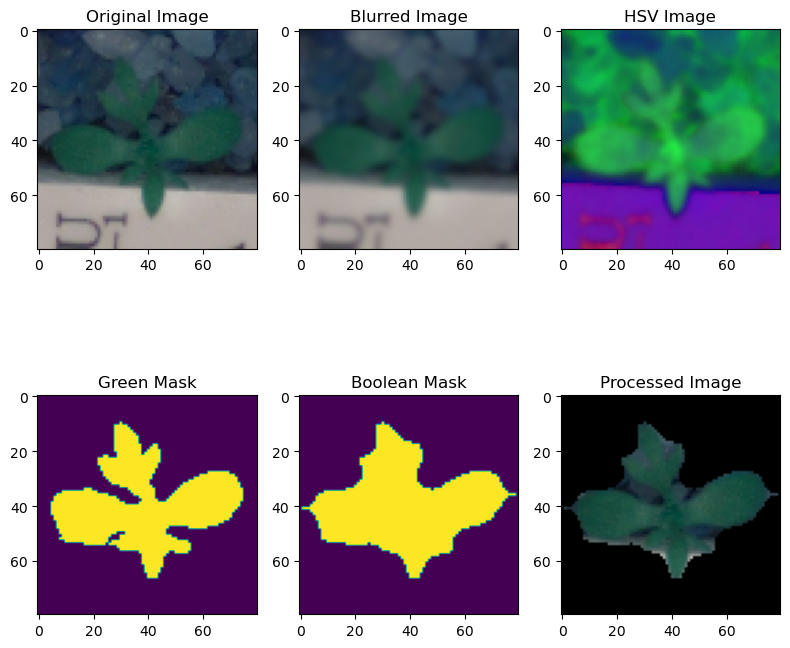

Example of some of processed images:


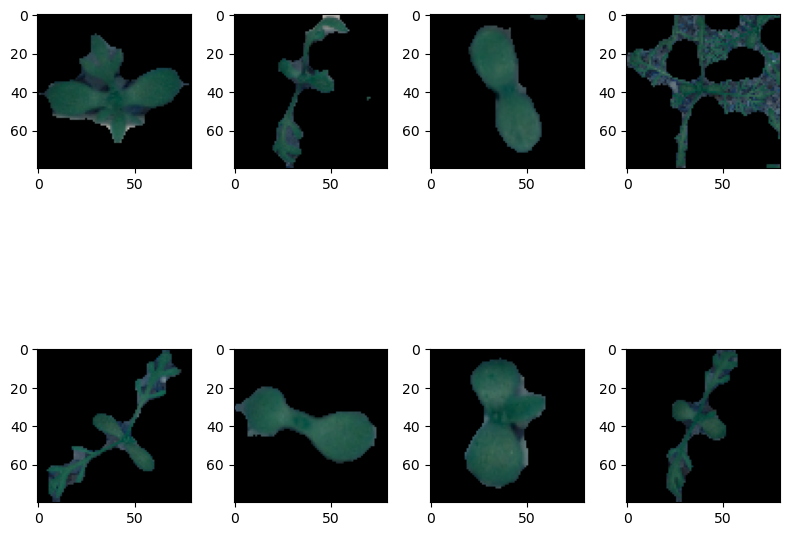

In [ ]:
from sklearn import preprocessing
from keras.utils import np_utils
import matplotlib.pyplot as plt

# Initialize a list to store the processed images
processed_images = []

# This variable will be used to control whether to display example images
show_examples = True

# Loop over each image in the training set
for image in training_images:
    # Apply Gaussian blur to the image
    blurred_image = cv2.GaussianBlur(image, (5, 5), 0)

    # Convert the image from BGR to HSV color space
    hsv_image = cv2.cvtColor(blurred_image, cv2.COLOR_BGR2HSV)

    # Define the range of green color in HSV
    green_lower_range = (25, 40, 50)
    green_upper_range = (75, 255, 255)

    # Create a mask for the green color
    green_mask = cv2.inRange(hsv_image, green_lower_range, green_upper_range)

    # Define the structuring element for the morphological operations
    structuring_element = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))

    # Apply morphological closing to the mask
    closed_mask = cv2.morphologyEx(green_mask, cv2.MORPH_CLOSE, structuring_element)

    # Create a boolean mask where green pixels are True
    boolean_mask = closed_mask > 0

    # Create a new image where only the green pixels are kept
    processed_image = np.zeros_like(image, np.uint8)
    processed_image[boolean_mask] = image[boolean_mask]

    # Add the processed image to the list
    processed_images.append(processed_image)

    # If show_examples is True, display the original and processed images
    if show_examples:
        plt.figure(figsize=(8, 8))

        plt.subplot(2, 3, 1)
        plt.imshow(image)
        plt.title("Original Image")

        plt.subplot(2, 3, 2)
        plt.imshow(blurred_image)
        plt.title("Blurred Image")

        plt.subplot(2, 3, 3)
        plt.imshow(hsv_image)
        plt.title("HSV Image")

        plt.subplot(2, 3, 4)
        plt.imshow(green_mask)
        plt.title("Green Mask")

        plt.subplot(2, 3, 5)
        plt.imshow(boolean_mask)
        plt.title("Boolean Mask")

        plt.subplot(2, 3, 6)
        plt.imshow(processed_image)
        plt.title("Processed Image")

        plt.tight_layout()
        plt.show()

        # Set show_examples to False so that we only display the examples once
        show_examples = False

# Convert the list of processed images to a numpy array
processed_images = np.array(processed_images)

# Display some of the processed images

print("Example of some of processed images:")

plt.figure(figsize=(8, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(processed_images[i])

plt.tight_layout()
plt.show()

## ****1.2 EDA - Type of the plant distribution of the Dataset****

In this part we are analyzing the training labels of a plant seedlings classification task. We print the unique classes, transform the labels into numerical encoded format for machine learning, and convert them to one-hot encoding. Then, we visualize the label distribution using a horizontal bar chart, helping us understand the number of classes and their respective occurrences in the dataset for better model preparation and analysis

Classes: ['Black-grass' 'Charlock' 'Cleavers' 'Common Chickweed' 'Common wheat'
 'Fat Hen' 'Loose Silky-bent' 'Maize' 'Scentless Mayweed'
 'Shepherds Purse' 'Small-flowered Cranesbill' 'Sugar beet']
Number of classes: 12


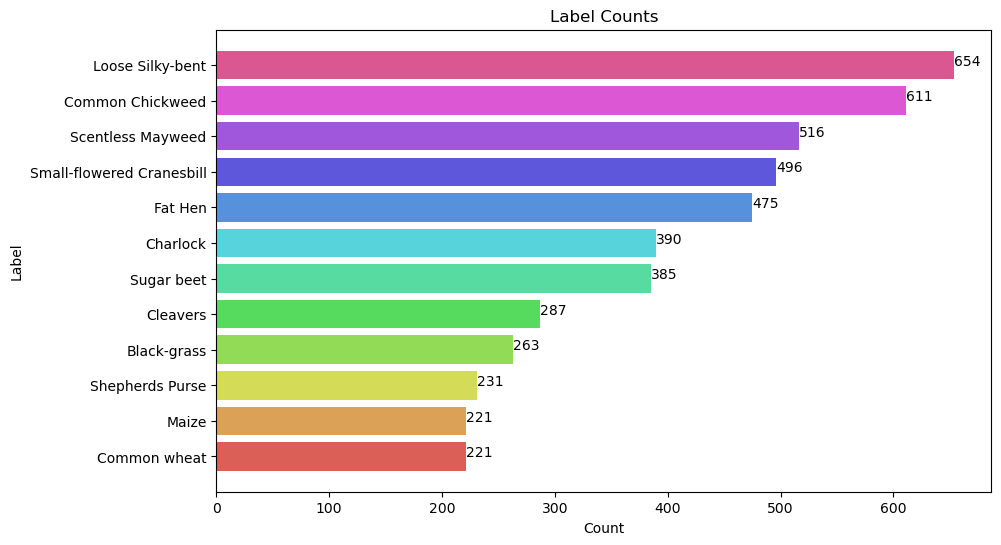

In [ ]:
from sklearn import preprocessing
from keras.utils import np_utils
import matplotlib.pyplot as plt
import seaborn as sns

# Check if SciPy version is compatible
import scipy
if scipy.__version__ >= '1.16.5' and scipy.__version__ < '1.23.0':
    # Suppress the warning about the SciPy version
    import warnings
    warnings.filterwarnings("ignore", message="A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy")

# Check TensorFlow IO warning
try:
    import tensorflow_io  # noqa
except ImportError:
    print("Warning: TensorFlow IO package not found. Some features may not work properly.")

# Initialize a label encoder
label_encoder = preprocessing.LabelEncoder()

# Fit the label encoder on the training labels
try:
    label_encoder.fit(training_labels['label'])
except KeyError:
    raise KeyError("Error: 'label' column not found in training_labels DataFrame. Please make sure the column name is correct.")

# Print the classes
print('Classes: ' + str(label_encoder.classes_))

# Transform the training labels to encoded labels
encoded_labels = label_encoder.transform(training_labels['label'])

# Convert the encoded labels to one-hot encoding
one_hot_labels = np_utils.to_categorical(encoded_labels)

# Get the number of classes
num_classes = one_hot_labels.shape[1]
print('Number of classes: ' + str(num_classes))

# Get the label counts and sort them in descending order
label_counts = training_labels['label'].value_counts().sort_values(ascending=True)

# Generate a color palette with different colors
palette = sns.color_palette("hls", len(label_counts))

# Plot a horizontal bar chart of the label counts with different colors
plt.figure(figsize=(10, 6))
plt.barh(label_counts.index, label_counts.values, color=palette)

# Add data labels to the bar chart
for index, value in enumerate(label_counts):
    plt.text(value, index, str(value))

plt.title("Label Counts")
plt.xlabel("Count")
plt.ylabel("Label")
plt.show()

It seems in train dataset contain images that represent all 12 classes, for each class we can see enough images which means this train dataset may not have issues like class imbalance

# ****2. CNN Model Building****

Now set the values of input from [0...255] to [0...1] (RGB color-space encode colors with numbers [0...255]). CNN will be faster train if we use [0...1] input

In [ ]:
# Normalize the input images to [0...1] range
processed_images = processed_images / 255.0

## ****2.1 CNN Model without using technique such as normalization, drop out and early stopping****

first let's create the CNN Model

For our first CNN model we are using 1 Convolutional layers with 1 pooling layers. Here we are not going to use technique such as normalization, drop out and early stopping, here for this model we are going to use 5 fold cross validation technique with activation function 'relu' and optimizer 'adam'. And we are going to use 64 fillters for only convoluational layer use here. Here we are using 2 fully connected layer with output layer with softmax activation function.

In our 2nd CNN model we are using 2 Convolutional layers with 2 pooling layers, to see the effect of increasing layers, other hypoparameters are same. (Here we use 64,and 128 fillters)

In our 3rd model we are using 3 Convolutional layers with 3 pooling layers (Here we use 64,128 and 256 filters) and epochs increased from 20 to 30, to see the effect of increasing layers as well as epochs, other hypoparameters are same.

In [ ]:
from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import pandas as pd
import numpy as np

from tensorflow.keras.layers import BatchNormalization, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau

import os
from tensorflow.keras.models import load_model

seed = 7

def create_model(activation, optimizer,num_conv_layers):
    # Initialize the model
    model = Sequential()

    if num_conv_layers == 1:

        # First convolutional block
        model.add(Conv2D(filters=64, kernel_size=(3, 3), input_shape=(scale, scale, 3), activation=activation))
        model.add(MaxPooling2D((2, 2)))

    elif num_conv_layers == 2:

        # First convolutional block
        model.add(Conv2D(filters=64, kernel_size=(3, 3), input_shape=(scale, scale, 3), activation=activation))
        model.add(MaxPooling2D((2, 2)))

        # Second convolutional block
        model.add(Conv2D(filters=128, kernel_size=(3, 3), activation=activation))
        model.add(MaxPooling2D((2, 2)))

    else:
        # First convolutional block
        model.add(Conv2D(filters=64, kernel_size=(3, 3), input_shape=(scale, scale, 3), activation=activation))
        model.add(MaxPooling2D((2, 2)))

        # Second convolutional block
        model.add(Conv2D(filters=128, kernel_size=(3, 3), activation=activation))
        model.add(MaxPooling2D((2, 2)))

        # Third convolutional block
        model.add(Conv2D(filters=256, kernel_size=(3, 3), activation=activation))
        model.add(MaxPooling2D((2, 2)))


    # Flatten the tensor output from the previous layer
    model.add(Flatten())

    # Fully connected block
    model.add(Dense(256, activation=activation))
    model.add(Dense(256, activation=activation))

    # Output layer with softmax activation function for multi-class classification
    model.add(Dense(num_classes, activation='softmax'))

    # Compile the model with categorical crossentropy loss for multi-class classification
    model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    return model

In [ ]:
# Import confusion_matrix here
from sklearn.metrics import confusion_matrix

def run_model(activation, optimizer, num_conv_layers, epochs):

    # Define the path to save the model
    model_path = f"/kaggle/working/model{num_conv_layers}-adam-relu.h5"

    # Define 5-fold cross validation
    kfold = KFold(n_splits=5, shuffle=True, random_state=seed)

    # Initialize a list to store the accuracy of each fold
    accuracies = []
    confusion_matrices = []
    fold_no = 1

    # Define learning rate reduction
    lrr = ReduceLROnPlateau(monitor='val_accuracy',
                            patience=3,
                            verbose=1,
                            factor=0.4,
                            min_lr=0.00001)

    # Check if the model already exists
    if os.path.exists(model_path):
        print("Loading existing model...")
        model = load_model(model_path)
    else:
        print("Creating and training a new model...")
        model = create_model(activation, optimizer, num_conv_layers)  # Pass num_conv_layers to create_model

        # Loop over each fold
        for train_indices, test_indices in kfold.split(processed_images, one_hot_labels):
            print(f"Running Fold {fold_no}")

            # Split data
            train_data, test_data = processed_images[train_indices], processed_images[test_indices]
            train_labels, test_labels = one_hot_labels[train_indices], one_hot_labels[test_indices]

            # Initialize the image data generator
            generator = ImageDataGenerator(rotation_range = 180,
                                           zoom_range = 0.1,
                                           width_shift_range = 0.1,
                                           height_shift_range = 0.1,
                                           horizontal_flip = True,
                                           vertical_flip = True)
            generator.fit(train_data)

            np.random.seed(seed)

            # Fit the model on the batches generated by datagen.flow().
            history = model.fit(generator.flow(train_data, train_labels, batch_size=32),
                                epochs=epochs,
                                validation_data=(test_data, test_labels),
                                callbacks=[lrr])

            # Get the final accuracy of the current fold
            accuracy = history.history['val_accuracy'][-1]
            accuracies.append(accuracy)
            print(f"Fold {fold_no} - Accuracy: {accuracy * 100:.2f}%")
            fold_no += 1

            # Get the test labels and predictions for the current fold
            test_labels_fold = np.argmax(test_labels, axis=1)
            test_predictions_fold = model.predict(test_data)
            test_predictions_fold = np.argmax(test_predictions_fold, axis=1)

            # Create the confusion matrix for the current fold
            cm = confusion_matrix(test_labels_fold, test_predictions_fold)
            confusion_matrices.append(cm)

        # Save the trained model
        model.save(model_path)

    # Calculate the average accuracy
    avg_accuracy = np.mean(accuracies)
    print(f"Average accuracy: {avg_accuracy * 100:.2f}%")

    return confusion_matrices

# Run the model with 'relu' activation function, 'adam' optimizer, 1 convolutional layer, and 20 epochs
confusion_matrices = run_model('relu', 'adam', 1, 20)

# Calculate and print the average confusion matrix
avg_confusion_matrix = np.mean(confusion_matrices, axis=0)
print("Average Confusion Matrix:")
print(avg_confusion_matrix)

# Plot the average confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(avg_confusion_matrix, annot=True, cmap='Blues', fmt='.0f')  # Changed format to '.0f' for integer values

# Get the class names from the label encoder
class_names = label_encoder.classes_

# Set the class names as the labels on the x and y axes
plt.xticks(np.arange(len(class_names)) + 0.5, class_names, rotation=90)
plt.yticks(np.arange(len(class_names)) + 0.5, class_names, rotation=0)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Average Confusion Matrix")
plt.show()

Based on our 1st CNN model we can see Average accuracy over 5 folds was 80.84%, and We can see Loose Skilly-bent Image class recognized incorrectly as Black-grass for 37 instances which cause to low accuracy

# Run the model with 'relu' activation function, 'adam' optimizer, 2 convolutional layer, and 20 epochs
confusion_matrices = run_model('relu', 'adam', 2, 20)

# Calculate and print the average confusion matrix
avg_confusion_matrix = np.mean(confusion_matrices, axis=0)
print("Confusion Matrix for Model 2:")

# Plot the average confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(avg_confusion_matrix, annot=True, cmap='Blues', fmt='.0f')  # Changed format to '.0f' for integer values

# Get the class names from the label encoder
class_names = label_encoder.classes_

# Set the class names as the labels on the x and y axes
plt.xticks(np.arange(len(class_names)) + 0.5, class_names, rotation=90)
plt.yticks(np.arange(len(class_names)) + 0.5, class_names, rotation=0)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix for Model 2")
plt.show()

Based on our 2nd CNN model we can see Average accuracy over 5 folds was 82.65%, and We can see Loose Skilly-bent Image class recognized incorrectly as Black-grass for 31 instances here, Also we can see some misclassification in other class as well. howevery accuracy has improved whcih indicate that when we increase the number of convolutional layers with Max pooling layers accuracy of the model also improved

>

# Run the model with 'relu' activation function, 'adam' optimizer, 3 convolutional layer, and 35 epochs
confusion_matrices = run_model('relu', 'adam', 3, 35)

# Calculate and print the average confusion matrix
avg_confusion_matrix = np.mean(confusion_matrices, axis=0)
print("Confusion Matrix for Model 2:")

# Plot the average confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(avg_confusion_matrix, annot=True, cmap='Blues', fmt='.0f')  # Changed format to '.0f' for integer values

# Get the class names from the label encoder
class_names = label_encoder.classes_

# Set the class names as the labels on the x and y axes
plt.xticks(np.arange(len(class_names)) + 0.5, class_names, rotation=90)
plt.yticks(np.arange(len(class_names)) + 0.5, class_names, rotation=0)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix for Model 3")
plt.show()

Based on our 3rd CNN model we can see Average accuracy over 5 folds was 90.99%, and We can see Loose Skilly-bent Image class recognized incorrectly as Black-grass for 17 instances only, however for othe classes we can see significance reduction in misclassification. Accuracy has improved over the 2nd CNN model, but here we should notice that we have not use any technique such as Normalization, Dropout. Let's see when we apply such technique improvement of the accuracy. Also, we noticed that when increase the epochs there is considerable impact in our train model set, therefore, we will keep epochs = 35 for next CNN model.

## ****2.2 CNN Model with using technique such as normalization, drop out and Early stopping****

Here, we are going to use the normalization, drop out and Early stopping with our model to see if there any improvment over our previous attempt with 3 convolutional layer case. Here, we keep epoch count as 30. And use same hypoparameters as model 3

In [ ]:
from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import pandas as pd
import numpy as np

from tensorflow.keras.layers import BatchNormalization, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau

import os
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import SpatialDropout2D

seed = 7

def create_model(activation, optimizer):
    # Initialize the model
    model_nd = Sequential()

    # First convolutional block
    model_nd.add(Conv2D(filters=64, kernel_size=(3, 3), input_shape=(scale, scale, 3), activation=activation))
    # Add the first pooling layer
    model_nd.add(MaxPooling2D((2, 2)))
    # Batch normalization and dropout for regularization
    model_nd.add(BatchNormalization(axis=3))
    model_nd.add(SpatialDropout2D(0.1))

    # Second convolutional block
    model_nd.add(Conv2D(filters=128, kernel_size=(3, 3), activation=activation))
    # Add the second pooling layer
    model_nd.add(MaxPooling2D((2, 2)))
    # Batch normalization and dropout for regularization
    model_nd.add(BatchNormalization(axis=3))
    model_nd.add(SpatialDropout2D(0.1))

    # Third convolutional block
    model_nd.add(Conv2D(filters=256, kernel_size=(3, 3), activation=activation))
    # Add the third pooling layer
    model_nd.add(MaxPooling2D((2, 2)))
    # Batch normalization and dropout for regularization
    model_nd.add(BatchNormalization(axis=3))
    model_nd.add(SpatialDropout2D(0.1))

    # Flatten the tensor output from the previous layer
    model_nd.add(Flatten())

    # Fully connected block
    model_nd.add(Dense(256, activation=activation))
    model_nd.add(Dense(256, activation=activation))

    # Output layer with softmax activation function for multi-class classification
    model_nd.add(Dense(num_classes, activation='softmax'))

    # Compile the model with categorical crossentropy loss for multi-class classification
    model_nd.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    return model_nd

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix

def run_model(activation, optimizer, epochs):

    # Define the path to save the model
    model_path_nd = f"/kaggle/working/model-normalization-droput-{optimizer}-{activation}.h5"

    # Define 5-fold cross validation
    kfold = KFold(n_splits=5, shuffle=True, random_state=seed)

    # Initialize a list to store the accuracy of each fold
    accuracies = []
    confusion_matrices = []
    fold_no = 1

    # Define learning rate reduction
    lrr = ReduceLROnPlateau(monitor='val_accuracy',
                            patience=3,
                            verbose=1,
                            factor=0.4,
                            min_lr=0.00001)

    # Define Early stopping
    es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=10)

    # Check if the model already exists
    if os.path.exists(model_path_nd):
        print("Loading existing model...")
        model_nd = load_model(model_path_nd)
    else:
        print("Creating and training a new model...")
        model_nd = create_model(activation, optimizer)

        # Loop over each fold
        for train_indices, test_indices in kfold.split(processed_images, one_hot_labels):
            print(f"Running Fold {fold_no}")

            # Split data
            train_data, test_data = processed_images[train_indices], processed_images[test_indices]
            train_labels, test_labels = one_hot_labels[train_indices], one_hot_labels[test_indices]

            # Initialize the image data generator
            generator = ImageDataGenerator(rotation_range = 180,
                                           zoom_range = 0.1,
                                           width_shift_range = 0.1,
                                           height_shift_range = 0.1,
                                           horizontal_flip = True,
                                           vertical_flip = True)
            generator.fit(train_data)

            np.random.seed(seed)

            # Fit the model on the batches generated by datagen.flow().
            history = model_nd.fit(generator.flow(train_data, train_labels, batch_size=32),
                                epochs=epochs,
                                validation_data=(test_data, test_labels),
                                callbacks=[lrr, es])

            # Get the final accuracy of the current fold
            accuracy = history.history['val_accuracy'][-1]
            accuracies.append(accuracy)
            print(f"Fold {fold_no} - Accuracy: {accuracy * 100:.2f}%")
            fold_no += 1

            # Get the test labels and predictions for the current fold
            test_labels_fold = np.argmax(test_labels, axis=1)
            test_predictions_fold = model_nd.predict(test_data)
            test_predictions_fold = np.argmax(test_predictions_fold, axis=1)

            # Create the confusion matrix for the current fold
            cm = confusion_matrix(test_labels_fold, test_predictions_fold)
            confusion_matrices.append(cm)

        # Save the trained model
        model_nd.save(model_path_nd)

    # Calculate the average accuracy
    avg_accuracy = np.mean(accuracies)
    print(f"Average accuracy: {avg_accuracy * 100:.2f}%")

    return confusion_matrices

# Run the model with 'relu' activation function, 'adam' optimizer, 3 convolutional layer, and 35 epochs
confusion_matrices = run_model('relu', 'adam', 35)

# Calculate and print the average confusion matrix
avg_confusion_matrix = np.mean(confusion_matrices, axis=0)
print("Confusion Matrix for Model 4 with Normalization, Dropout, and Early Stopping:")

# Plot the average confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(avg_confusion_matrix, annot=True, cmap='Blues', fmt='.0f')  # Changed format to '.0f' for integer values

# Get the class names from the label encoder
class_names = label_encoder.classes_

# Set the class names as the labels on the x and y axes
plt.xticks(np.arange(len(class_names)) + 0.5, class_names, rotation=90)
plt.yticks(np.arange(len(class_names)) + 0.5, class_names, rotation=0)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix for Model 4 with Normalization Dropout, and Early Stopping")
plt.show()

Here we can see clear improvement over our 3rd model, Avg. Accuracy over 5 folds is 90.34% which is a slighty lower accuracy score than our Model 3. This could be due to Early stopping

Here, we try same configuration but this time without using Early stoppoing, and also we did change dropout to 0.3

In [ ]:
from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import pandas as pd
import numpy as np

from tensorflow.keras.layers import BatchNormalization, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau

import os
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import SpatialDropout2D

seed = 7

def create_model(activation, optimizer):
    # Initialize the model
    model_nd = Sequential()

    # First convolutional block
    model_nd.add(Conv2D(filters=64, kernel_size=(3, 3), input_shape=(scale, scale, 3), activation=activation))
    # Add the first pooling layer
    model_nd.add(MaxPooling2D((2, 2)))
    # Batch normalization and dropout for regularization
    model_nd.add(BatchNormalization(axis=3))
    model_nd.add(SpatialDropout2D(0.3))

    # Second convolutional block
    model_nd.add(Conv2D(filters=128, kernel_size=(3, 3), activation=activation))
    # Add the second pooling layer
    model_nd.add(MaxPooling2D((2, 2)))
    # Batch normalization and dropout for regularization
    model_nd.add(BatchNormalization(axis=3))
    model_nd.add(SpatialDropout2D(0.3))

    # Third convolutional block
    model_nd.add(Conv2D(filters=256, kernel_size=(3, 3), activation=activation))
    # Add the third pooling layer
    model_nd.add(MaxPooling2D((2, 2)))
    # Batch normalization and dropout for regularization
    model_nd.add(BatchNormalization(axis=3))
    model_nd.add(SpatialDropout2D(0.3))

    # Flatten the tensor output from the previous layer
    model_nd.add(Flatten())

    # Fully connected block
    model_nd.add(Dense(256, activation=activation))
    model_nd.add(Dense(256, activation=activation))

    # Output layer with softmax activation function for multi-class classification
    model_nd.add(Dense(num_classes, activation='softmax'))

    # Compile the model with categorical crossentropy loss for multi-class classification
    model_nd.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    return model_nd

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix

def run_model(activation, optimizer, epochs):

    # Define the path to save the model
    model_path_nd = f"/kaggle/working/model-normalization-droput-without-ES-{optimizer}-{activation}.h5"

    # Define 5-fold cross validation
    kfold = KFold(n_splits=5, shuffle=True, random_state=seed)

    # Initialize a list to store the accuracy of each fold
    accuracies = []
    confusion_matrices = []
    fold_no = 1

    # Define learning rate reduction
    lrr = ReduceLROnPlateau(monitor='val_accuracy',
                            patience=3,
                            verbose=1,
                            factor=0.4,
                            min_lr=0.00001)

    # Check if the model already exists
    if os.path.exists(model_path_nd):
        print("Loading existing model...")
        model_nd = load_model(model_path_nd)
    else:
        print("Creating and training a new model...")
        model_nd = create_model(activation, optimizer)

        # Loop over each fold
        for train_indices, test_indices in kfold.split(processed_images, one_hot_labels):
            print(f"Running Fold {fold_no}")

            # Split data
            train_data, test_data = processed_images[train_indices], processed_images[test_indices]
            train_labels, test_labels = one_hot_labels[train_indices], one_hot_labels[test_indices]

            # Initialize the image data generator
            generator = ImageDataGenerator(rotation_range = 180,
                                           zoom_range = 0.1,
                                           width_shift_range = 0.1,
                                           height_shift_range = 0.1,
                                           horizontal_flip = True,
                                           vertical_flip = True)
            generator.fit(train_data)

            np.random.seed(seed)

            # Fit the model on the batches generated by datagen.flow().
            history = model_nd.fit(generator.flow(train_data, train_labels, batch_size=32),
                                epochs=epochs,
                                validation_data=(test_data, test_labels),
                                callbacks=[lrr])

            # Get the final accuracy of the current fold
            accuracy = history.history['val_accuracy'][-1]
            accuracies.append(accuracy)
            print(f"Fold {fold_no} - Accuracy: {accuracy * 100:.2f}%")
            fold_no += 1

            # Get the test labels and predictions for the current fold
            test_labels_fold = np.argmax(test_labels, axis=1)
            test_predictions_fold = model_nd.predict(test_data)
            test_predictions_fold = np.argmax(test_predictions_fold, axis=1)

            # Create the confusion matrix for the current fold
            cm = confusion_matrix(test_labels_fold, test_predictions_fold)
            confusion_matrices.append(cm)

        # Save the trained model
        model_nd.save(model_path_nd)

    # Calculate the average accuracy
    avg_accuracy = np.mean(accuracies)
    print(f"Average accuracy: {avg_accuracy * 100:.2f}%")

    return confusion_matrices

# Run the model with 'relu' activation function, 'adam' optimizer, 3 convolutional layer, and 35 epochs
confusion_matrices = run_model('relu', 'adam', 35)

# Calculate and print the average confusion matrix
avg_confusion_matrix = np.mean(confusion_matrices, axis=0)
print("Confusion Matrix for Model 4 with Normalization, Dropout:")

# Plot the average confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(avg_confusion_matrix, annot=True, cmap='Blues', fmt='.0f')  # Changed format to '.0f' for integer values

# Get the class names from the label encoder
class_names = label_encoder.classes_

# Set the class names as the labels on the x and y axes
plt.xticks(np.arange(len(class_names)) + 0.5, class_names, rotation=90)
plt.yticks(np.arange(len(class_names)) + 0.5, class_names, rotation=0)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix for Model 4 with Normalization Dropout")
plt.show()

Accuracy dropped to 88.08% which indicated that early stopping is clearly helpful.

## ****3. Using already trained CNN model****

Here we are going to use VGG-19, RestNet50 (Already trained CNN) model and retrain it's last few layers

In [ ]:
from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import pandas as pd
import numpy as np
from tensorflow.keras.layers import BatchNormalization, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau
import os
from tensorflow.keras.models import load_model

from tensorflow.keras.applications import VGG19, ResNet50, Xception, ResNet50V2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model

def create_transfer_model(base_model_name, activation, optimizer):
    # Select the base model
    if base_model_name == 'VGG19':
        base_model = VGG19(weights='imagenet', include_top=False, input_shape=(scale, scale, 3))
    elif base_model_name == 'ResNet50':
        base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(scale, scale, 3))
    elif base_model_name == 'Xception':
        base_model = Xception(weights='imagenet', include_top=False, input_shape=(scale, scale, 3))
    elif base_model_name == 'ResNet50V2':
        base_model = ResNet50V2(weights='imagenet', include_top=False, input_shape=(scale, scale, 3))
    else:
        print(f"Unknown base model: {base_model_name}")
        return None

    base_model.trainable = False

    # Define the new model

    model = Sequential([
        base_model,

        #Add Max Pooling Layer
        GlobalAveragePooling2D(),

        #Add 2 dense layers
        Dense(100, activation=activation),
        Dense(50, activation=activation),

        #Add output layer
        Dense(num_classes, activation='softmax')
    ])

     # Compile the model

    model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    return model

In [ ]:
from sklearn.metrics import confusion_matrix

seed = 7

def run_model(model, base_model_name, activation, optimizer, epochs):
    # Define the path to save the model
    model_path = f"/kaggle/working/model-{base_model_name}.h5"

    # Define 5-fold cross validation
    kfold = KFold(n_splits=5, shuffle=True, random_state=seed)

    # Initialize a list to store the accuracy of each fold
    accuracies = []
    confusion_matrices = []
    fold_no = 1

    # Define learning rate reduction
    lrr = ReduceLROnPlateau(monitor='val_accuracy',
                            patience=3,
                            verbose=1,
                            factor=0.4,
                            min_lr=0.00001)

    # Check if the model already exists
    if os.path.exists(model_path):
        print("Loading existing model...")
        model = load_model(model_path)
    else:
        print("Training a new model...")
        model = create_transfer_model(base_model_name, activation, optimizer)

        # Loop over each fold
        for train_indices, test_indices in kfold.split(processed_images, one_hot_labels):
            print(f"Running Fold {fold_no}")

            # Split data
            train_data, test_data = processed_images[train_indices], processed_images[test_indices]
            train_labels, test_labels = one_hot_labels[train_indices], one_hot_labels[test_indices]

            # Initialize the image data generator
            generator = ImageDataGenerator(rotation_range = 360,
                                           zoom_range = 0.3,
                                           width_shift_range = 0.3,
                                           height_shift_range = 0.3,
                                           horizontal_flip = True,
                                           vertical_flip = True)
            generator.fit(train_data)

            np.random.seed(seed)

            # Fit the model on the batches generated by datagen.flow().
            history = model.fit(generator.flow(train_data, train_labels, batch_size=32),
                                epochs=epochs,
                                validation_data=(test_data, test_labels),
                                callbacks=[lrr])

            # Get the final accuracy of the current fold
            accuracy = history.history['val_accuracy'][-1]
            accuracies.append(accuracy)
            print(f"Fold {fold_no} - Accuracy: {accuracy * 100:.2f}%")
            fold_no += 1

            # Get the test labels and predictions for the current fold
            test_labels_fold = np.argmax(test_labels, axis=1)
            test_predictions_fold = model.predict(test_data)
            test_predictions_fold = np.argmax(test_predictions_fold, axis=1)

            # Create the confusion matrix for the current fold
            cm = confusion_matrix(test_labels_fold, test_predictions_fold)
            confusion_matrices.append(cm)

        # Save the trained model
        model.save(model_path)

    # Calculate the average accuracy
    avg_accuracy = np.mean(accuracies)
    print(f"Average accuracy: {avg_accuracy * 100:.2f}%")

    return confusion_matrices

# Run the model with 'relu' activation function, 'adam' optimizer, and 20 epochs
for base_model_name in ['VGG19', 'ResNet50','Xception','ResNet50V2' ]:
    print(f"Training model based on {base_model_name}")
    model = create_transfer_model(base_model_name, 'relu', 'adam')
    confusion_matrices = run_model(model, base_model_name, 'relu', 'adam', 35)

    # Calculate and print the average confusion matrix
    avg_confusion_matrix = np.mean(confusion_matrices, axis=0)
    print(f"Average Confusion Matrix for {base_model_name}:")
    print(avg_confusion_matrix)

    # Plot the average confusion matrix as a heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(avg_confusion_matrix, annot=True, cmap='Blues', fmt='.0f')  # Changed format to '.0f' for integer values

    # Get the class names from the label encoder
    class_names = label_encoder.classes_

    # Set the class names as the labels on the x and y axes
    plt.xticks(np.arange(len(class_names)) + 0.5, class_names, rotation=90)
    plt.yticks(np.arange(len(class_names)) + 0.5, class_names, rotation=0)

    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.title(f"Average Confusion Matrix for {base_model_name}")
    plt.show()

It seems already train CNN models did not work well with train images, this is due to we use low scale px count for train images (80 x 80 px). CNN model such as Xception required high quality images to perform well, if we increase the scale we would be able to get high accuracy with already train CNN model, since we are running this code inside the kaggle console, availale RAM is not enough. If you run this code inside your local environment with higher scale you would come up with more than 95% accuracy for trained CNN model. Also, we noticed RestNet50 model work very poorely and provide very low accuracy. Therefore, we decide to go with our train CNN model to predict the label of the test datasets.

Here, we run our CNN model with increasing number of Convolutional layers to 6, to see is there any improvment with Accuracy, previously we achived 90.99% accuracy with our 3rd CNN model which has 3 Covolutional layers.

Let's build the model again with 6 conv. layers and 3 max pooling layers

First we try without Normalization and dropout,and Early stopping then we will try with that too

In [ ]:
from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import pandas as pd
import numpy as np

from tensorflow.keras.callbacks import ReduceLROnPlateau

import os
from tensorflow.keras.models import load_model

seed = 7

def create_model(activation, optimizer):
    # Initialize the model
    model_nd = Sequential()

    # First convolutional block
    model_nd.add(Conv2D(filters=64, kernel_size=(5, 5), input_shape=(scale, scale, 3), activation=activation))
    # Second Convolutional layer with 64 filters and 5x5 kernel
    model_nd.add(Conv2D(filters=64, kernel_size=(5, 5), activation=activation))
    # Add the first pooling layer
    model_nd.add(MaxPooling2D((2, 2)))


    # Third convolutional block
    model_nd.add(Conv2D(filters=128, kernel_size=(5, 5), activation=activation))
    # Fourth Convolutional layer with 64 filters and 5x5 kernel
    model_nd.add(Conv2D(filters=128, kernel_size=(5, 5), activation=activation))
    # Add the second pooling layer
    model_nd.add(MaxPooling2D((2, 2)))

    # Fifth convolutional block
    model_nd.add(Conv2D(filters=256, kernel_size=(5, 5), activation=activation))
    # Sixeth Convolutional layer with 64 filters and 5x5 kernel
    model_nd.add(Conv2D(filters=256, kernel_size=(5, 5), activation=activation))
    # Add the third pooling layer
    model_nd.add(MaxPooling2D((2, 2)))

    # Flatten the tensor output from the previous layer
    model_nd.add(Flatten())

    # Fully connected block
    model_nd.add(Dense(256, activation=activation))
    model_nd.add(Dense(256, activation=activation))

    # Output layer with softmax activation function for multi-class classification
    model_nd.add(Dense(num_classes, activation='softmax'))

    # Compile the model with categorical crossentropy loss for multi-class classification
    model_nd.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    return model_nd

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix

def run_model(activation, optimizer, epochs):

    # Define the path to save the model
    model_path_nd = f"/kaggle/working/model4-{optimizer}-{activation}.h5"

    # Define 5-fold cross validation
    kfold = KFold(n_splits=5, shuffle=True, random_state=seed)

    # Initialize a list to store the accuracy of each fold
    accuracies = []
    confusion_matrices = []
    fold_no = 1

    # Define learning rate reduction
    lrr = ReduceLROnPlateau(monitor='val_accuracy',
                            patience=3,
                            verbose=1,
                            factor=0.4,
                            min_lr=0.00001)


    # Check if the model already exists
    if os.path.exists(model_path_nd):
        print("Loading existing model...")
        model_nd = load_model(model_path_nd)
    else:
        print("Creating and training a new model...")
        model_nd = create_model(activation, optimizer)

        # Loop over each fold
        for train_indices, test_indices in kfold.split(processed_images, one_hot_labels):
            print(f"Running Fold {fold_no}")

            # Split data
            train_data, test_data = processed_images[train_indices], processed_images[test_indices]
            train_labels, test_labels = one_hot_labels[train_indices], one_hot_labels[test_indices]

            # Initialize the image data generator
            generator = ImageDataGenerator(rotation_range = 180,
                                           zoom_range = 0.1,
                                           width_shift_range = 0.1,
                                           height_shift_range = 0.1,
                                           horizontal_flip = True,
                                           vertical_flip = True)
            generator.fit(train_data)

            np.random.seed(seed)

            # Fit the model on the batches generated by datagen.flow().
            history = model_nd.fit(generator.flow(train_data, train_labels, batch_size=32),
                                epochs=epochs,
                                validation_data=(test_data, test_labels),
                                callbacks=[lrr])

            # Get the final accuracy of the current fold
            accuracy = history.history['val_accuracy'][-1]
            accuracies.append(accuracy)
            print(f"Fold {fold_no} - Accuracy: {accuracy * 100:.2f}%")
            fold_no += 1

            # Get the test labels and predictions for the current fold
            test_labels_fold = np.argmax(test_labels, axis=1)
            test_predictions_fold = model_nd.predict(test_data)
            test_predictions_fold = np.argmax(test_predictions_fold, axis=1)

            # Create the confusion matrix for the current fold
            cm = confusion_matrix(test_labels_fold, test_predictions_fold)
            confusion_matrices.append(cm)

        # Save the trained model
        model_nd.save(model_path_nd)

    # Calculate the average accuracy
    avg_accuracy = np.mean(accuracies)
    print(f"Average accuracy: {avg_accuracy * 100:.2f}%")

    return confusion_matrices

Creating and training a new model...
Running Fold 1
Epoch 1/35
119/119 [==============================] - 20s 77ms/step - loss: 2.0860 - accuracy: 0.2718 - val_loss: 1.7753 - val_accuracy: 0.3653 - lr: 0.0010
Epoch 2/35
119/119 [==============================] - 8s 64ms/step - loss: 1.7018 - accuracy: 0.3818 - val_loss: 1.5844 - val_accuracy: 0.4105 - lr: 0.0010
Epoch 3/35
119/119 [==============================] - 8s 65ms/step - loss: 1.5724 - accuracy: 0.4313 - val_loss: 1.3816 - val_accuracy: 0.4958 - lr: 0.0010
Epoch 4/35
119/119 [==============================] - 9s 72ms/step - loss: 1.4581 - accuracy: 0.4763 - val_loss: 1.4632 - val_accuracy: 0.4558 - lr: 0.0010
Epoch 5/35
119/119 [==============================] - 8s 66ms/step - loss: 1.3239 - accuracy: 0.5161 - val_loss: 1.2302 - val_accuracy: 0.5547 - lr: 0.0010
Epoch 6/35
119/119 [==============================] - 8s 66ms/step - loss: 1.2809 - accuracy: 0.5289 - val_loss: 1.1424 - val_accuracy: 0.5853 - lr: 0.0010
Epoch 7/35


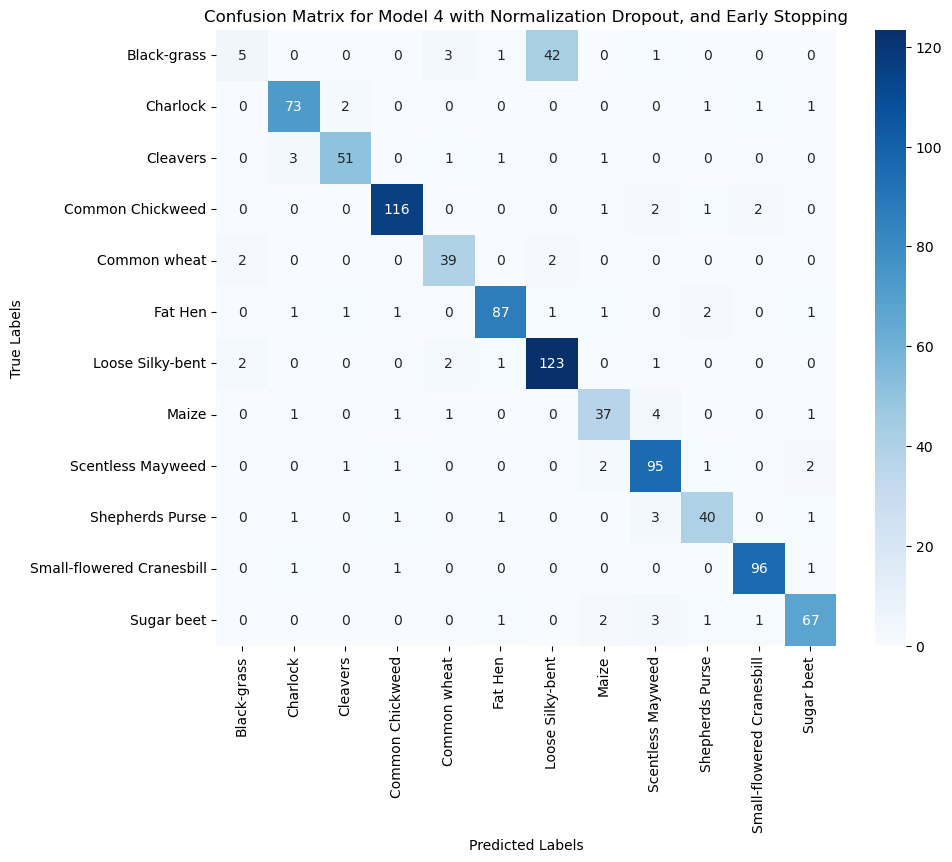

In [ ]:
# Run the model with 'relu' activation function, 'adam' optimizer, 3 convolutional layer, and 35 epochs
confusion_matrices = run_model('relu', 'adam', 35)

# Calculate and print the average confusion matrix
avg_confusion_matrix = np.mean(confusion_matrices, axis=0)
print("Confusion Matrix for Model 4 with Normalization, Dropout, and Early Stopping:")

# Plot the average confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(avg_confusion_matrix, annot=True, cmap='Blues', fmt='.0f')  # Changed format to '.0f' for integer values

# Get the class names from the label encoder
class_names = label_encoder.classes_

# Set the class names as the labels on the x and y axes
plt.xticks(np.arange(len(class_names)) + 0.5, class_names, rotation=90)
plt.yticks(np.arange(len(class_names)) + 0.5, class_names, rotation=0)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix for Model 4 with Normalization Dropout, and Early Stopping")
plt.show()

Here, we managed to increased the accuracy in very slighty than our 3rd model, model 4 scored Avg.Accuracy as 91.12%

Let's use Normalization and dropout technique to see if there is any improvment, Also, we reduced the intial learning rate to 0.0001 and min learning rate to 0.000005

In [ ]:
from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import pandas as pd
import numpy as np

from tensorflow.keras.callbacks import ReduceLROnPlateau

import os
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import BatchNormalization, Dropout
#from tensorflow.keras.layers import SpatialDropout2D

from tensorflow.keras.optimizers import Adam

seed = 7

def create_model(activation):
    # Initialize the model
    model_nd = Sequential()

    # First convolutional block
    model_nd.add(Conv2D(filters=64, kernel_size=(5, 5), input_shape=(scale, scale, 3), activation=activation))
    # Batch normalization
    model_nd.add(BatchNormalization(axis=3))
    # Second Convolutional layer with 64 filters and 5x5 kernel
    model_nd.add(Conv2D(filters=64, kernel_size=(5, 5), activation=activation))
    # Add the first pooling layer
    model_nd.add(MaxPooling2D((2, 2)))
    # Batch normalization
    model_nd.add(BatchNormalization(axis=3))
    # Droput
    model_nd.add(Dropout(0.1))

    # Third convolutional block
    model_nd.add(Conv2D(filters=128, kernel_size=(5, 5), activation=activation))
    # Batch normalization
    model_nd.add(BatchNormalization(axis=3))
    # Fourth Convolutional layer with 128 filters and 5x5 kernel
    model_nd.add(Conv2D(filters=128, kernel_size=(5, 5), activation=activation))
    # Add the second pooling layer
    model_nd.add(MaxPooling2D((2, 2)))
    # Batch normalization
    model_nd.add(BatchNormalization(axis=3))
    # Droput
    model_nd.add(Dropout(0.1))

    # Fifth convolutional block
    model_nd.add(Conv2D(filters=256, kernel_size=(5, 5), activation=activation))
    # Batch normalization
    model_nd.add(BatchNormalization(axis=3))
    # Sixeth Convolutional layer with 256 filters and 5x5 kernel
    model_nd.add(Conv2D(filters=256, kernel_size=(5, 5), activation=activation))
    # Add the third pooling layer
    model_nd.add(MaxPooling2D((2, 2)))
    # Batch normalization
    model_nd.add(BatchNormalization(axis=3))
    #Droput
    model_nd.add(Dropout(0.1))

    # Flatten the tensor output from the previous layer
    model_nd.add(Flatten())

    # Fully connected block
    model_nd.add(Dense(256, activation=activation))
    model_nd.add(BatchNormalization())
    model_nd.add(Dropout(0.5))

    model_nd.add(Dense(256, activation=activation))
    model_nd.add(BatchNormalization())
    model_nd.add(Dropout(0.5))


    # Output layer with softmax activation function for multi-class classification
    model_nd.add(Dense(num_classes, activation='softmax'))

    # Define the optimizer with the specified initial learning rate
    optimizer = Adam(learning_rate=0.0001)

    # Compile the model with categorical crossentropy loss for multi-class classification
    model_nd.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    return model_nd

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix

def run_model(activation, epochs):
    # Define the path to save the model
    model_path_nd = f"/kaggle/working/model4-normalization-droput-ES-{activation}.h5"

    # Define 5-fold cross validation
    kfold = KFold(n_splits=5, shuffle=True, random_state=seed)

    # Initialize a list to store the accuracy of each fold
    accuracies = []
    confusion_matrices = []
    fold_no = 1

    # Define learning rate reduction
    lrr = ReduceLROnPlateau(monitor='val_accuracy',
                            patience=5,
                            verbose=1,
                            factor=0.4,
                            min_lr=0.000005)

    # Define early stopping
    es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)

    # Check if the model already exists
    if os.path.exists(model_path_nd):
        print("Loading existing model...")
        model_nd = load_model(model_path_nd)
    else:
        print("Creating and training a new model...")
        model_nd = create_model(activation)

        # Loop over each fold
        for train_indices, test_indices in kfold.split(processed_images, one_hot_labels):
            print(f"Running Fold {fold_no}")

            # Split data
            train_data, test_data = processed_images[train_indices], processed_images[test_indices]
            train_labels, test_labels = one_hot_labels[train_indices], one_hot_labels[test_indices]

            # Initialize the image data generator
            generator = ImageDataGenerator(rotation_range = 180,
                                           zoom_range = 0.1,
                                           width_shift_range = 0.1,
                                           height_shift_range = 0.1,
                                           horizontal_flip = True,
                                           vertical_flip = True)
            generator.fit(train_data)

            np.random.seed(seed)

            # Fit the model on the batches generated by datagen.flow().
            history = model_nd.fit(generator.flow(train_data, train_labels, batch_size=32),
                                epochs=epochs,
                                validation_data=(test_data, test_labels),
                                callbacks=[lrr, es] if fold_no > 1 else [lrr])

            # Get the final accuracy of the current fold
            accuracy = history.history['val_accuracy'][-1]
            accuracies.append(accuracy)
            print(f"Fold {fold_no} - Accuracy: {accuracy * 100:.2f}%")
            fold_no += 1

            # Get the test labels and predictions for the current fold
            test_labels_fold = np.argmax(test_labels, axis=1)
            test_predictions_fold = model_nd.predict(test_data)
            test_predictions_fold = np.argmax(test_predictions_fold, axis=1)

            # Create the confusion matrix for the current fold
            cm = confusion_matrix(test_labels_fold, test_predictions_fold)
            confusion_matrices.append(cm)

        # Save the trained model
        model_nd.save(model_path_nd)

    # Calculate the average accuracy
    avg_accuracy = np.mean(accuracies)
    print(f"Average accuracy: {avg_accuracy * 100:.2f}%")

    return confusion_matrices

# Run the model with 'relu' activation function and 35 epochs
confusion_matrices = run_model('relu', 35)

# Calculate and print the average confusion matrix
avg_confusion_matrix = np.mean(confusion_matrices, axis=0)
print("Confusion Matrix for Model 4 with Normalization, Dropout, ES:")

# Plot the average confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(avg_confusion_matrix, annot=True, cmap='Blues', fmt='.0f')  # Changed format to '.0f' for integer values

# Get the class names from the label encoder
class_names = label_encoder.classes_

# Set the class names as the labels on the x and y axes
plt.xticks(np.arange(len(class_names)) + 0.5, class_names, rotation=90)
plt.yticks(np.arange(len(class_names)) + 0.5, class_names, rotation=0)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix for 4 Model with Normalization Dropout, ES")
plt.show()

It seems, for this case these technique did not help to improve the model. Therefore we decided to use our best model 4 for predicting the test datasets.

## ****4. Predict Labels for Test dataset using our best model****

For, predicting the labels for our test dataset we are using our Model 3, since it has high accuracy, and please note that we comment training phase of all other model, otherwise it will take long time to run the code. However, we shared all of our train models and Jupyter notebook with all output with our source code.

In [ ]:
import os

# Load the trained model
from tensorflow.keras.models import load_model

model_path = '/kaggle/input/train-models-cnn/model4-adam-relu.h5'
model = load_model(model_path)

# Load the test data
test_image_file_path = '../input/plant-seedlings-classification/test/*.png'

# Get a list of all image file paths
test_image_files = glob(test_image_file_path)

# Print the number of image files found
print(f"Found {len(test_image_files)} image files")

# Initialize a list to store the test images and filenames
test_images = []
test_filenames = []

# Loop over each image file
for count, image_file in enumerate(test_image_files, start=1):
    print(f"Processing image {count} of {len(test_image_files)}", end='\r')

    # Read the image file and resize it
    image = cv2.resize(cv2.imread(image_file), (scale, scale))
    test_images.append(image)

    # Extract the filename from the file path
    test_filenames.append(image_file.split('/')[-1])  # Get image filename

# Convert the list to a numpy array for use with machine learning models
test_images = np.array(test_images)

# Print the shape of the test images
print(f"\nTest images shape: {test_images.shape}")

# Apply the same preprocessing steps to the test images as the training images
processed_test_images = []
for image in test_images:
    # Apply Gaussian blur to the image
    blurred_image = cv2.GaussianBlur(image, (5, 5), 0)

    # Convert the image from BGR to HSV color space
    hsv_image = cv2.cvtColor(blurred_image, cv2.COLOR_BGR2HSV)

    # Create a mask for the green color
    green_mask = cv2.inRange(hsv_image, green_lower_range, green_upper_range)

    # Apply morphological closing to the mask
    closed_mask = cv2.morphologyEx(green_mask, cv2.MORPH_CLOSE, structuring_element)

    # Create a boolean mask where green pixels are True
    boolean_mask = closed_mask > 0

    # Create a new image where only the green pixels are kept
    processed_image = np.zeros_like(image, np.uint8)
    processed_image[boolean_mask] = image[boolean_mask]

    # Add the processed image to the list
    processed_test_images.append(processed_image)

# Convert the list of processed images to a numpy array
processed_test_images = np.array(processed_test_images)

# Normalize the input images to [0...1] range
processed_test_images = processed_test_images / 255.0

# Make predictions on the test images
test_predictions = model.predict(processed_test_images)

# Convert the predictions to label indices
test_label_indices = np.argmax(test_predictions, axis=1)

# Convert the label indices to labels
test_labels = label_encoder.inverse_transform(test_label_indices)

# Create a DataFrame for the submission
submission = pd.DataFrame({
    'file': test_filenames,
    'species': test_labels
})

# Save the submission DataFrame to a CSV file
submission.to_csv('submission.csv', index=False)

# Print the first few rows of the submission DataFrame
print(submission.head())

Found 794 image files
Processing image 794 of 794
Test images shape: (794, 80, 80, 3)
25/25 [==============================] - 1s 17ms/step
            file           species
0  fd87b36ae.png  Loose Silky-bent
1  0e8492cb1.png             Maize
2  8d6acbe9b.png  Common Chickweed
3  54b3afd58.png          Cleavers
4  6049234e6.png           Fat Hen
